# MODULE 8 — FREQUENCY-DOMAIN SIGNAL ANALYSIS 🎵

**Core DSP Concept**

**Important for Speech AI**

In Module 7, we studied audio in the **time domain**: how the signal's amplitude changes over time.

Now we'll look at the same audio from a different perspective: the **frequency domain**.

The central question of this module is:

> What frequencies are present inside an audio signal, and how strong is each frequency?

This is fundamental to speech recognition, speaker recognition, speech enhancement, emotion recognition and almost every modern audio-processing system.

---

## 8.1 Time Domain vs Frequency Domain

Imagine recording someone saying the vowel sound **"AAAA"**.

A microphone converts the sound into an electrical signal. When we plot it, we get a waveform.

### Time-domain representation

- X-axis: Time (seconds)
- Y-axis: Amplitude
- Shows how the signal changes over time.
- Useful for observing silence, speech activity, amplitude and clipping.

![Time-domain audio waveform](https://images.openai.com/static-rsc-4/aSZ_io4mjDEqQJUj4OlFJrrJu63zzrU5HFJbL0O0QClMb6e3sHfNKZewkPvHqHq5jNUFme1eUJrseaNODHObqel1rJKn3NCVPIztsdwJXaaYVJfW2-IJTwDWnqzzYBgqoqABeRI_mQAVBGXacDiyGTV6WFv7ELyCwS40vwaQzZI?purpose=inline)

Reference: [Audio Processing with LSTM & VGGish — Medium](https://medium.com/%40spacenavard1/audio-processing-with-lstm-vggish-example-story-138f154162d7?utm_source=chatgpt.com)

### Frequency-domain representation

Instead of asking how amplitude changes over time, we ask which frequencies make up the signal.

- X-axis: Frequency (Hz)
- Y-axis: Magnitude or power
- Shows the frequency components present in the signal.
- Useful for identifying pitch-related components, harmonics, noise and spectral characteristics.

![Frequency-domain representation](https://images.openai.com/static-rsc-4/N_3Mtcrz6wTzgQTdAWwA85oQPqhuQZTKlJ_9ykMFsMRGdQdvnV4AKWqPj6w2zruMpbwTtWFedCMuKLleWIZw9GUEjn1USnJSswRmOjPJy-zrnwG888w7HPxmXGBkmJzvhj1t4P0szaWBTQKDIlAU79FUpHwgApWqzQaUUdD0SrU?purpose=inline)

Reference: [Fast Fourier Transform Explained from the DFT — Jien Weng](https://jienweng.github.io/notes/fft-sound-wave/?utm_source=chatgpt.com)

### Comparison

| Feature | Time domain | Frequency domain |
|---|---|---|
| X-axis | Time | Frequency |
| Y-axis | Amplitude | Magnitude or power |
| Main question | When does the signal change? | Which frequencies are present? |
| Common visualization | Waveform | Spectrum |
| Useful for | Silence, clipping, amplitude | Pitch, harmonics, noise |

**Important:** These are two representations of the same signal. Neither replaces the other.

---

## 8.2 Periodic Signals and Frequency Components

Before understanding Fourier analysis, we need to understand what a frequency component is.

A pure sinusoidal signal contains one frequency.

The mathematical representation is:

$$
x(t)=A\sin(2\pi ft+\phi)
$$

Where:

- $A$ = Amplitude
- $f$ = Frequency in Hz
- $t$ = Time in seconds
- $\phi$ = Phase in radians

### Example

$$
x(t)=\sin(2\pi \cdot 100t)
$$

This represents a sine wave with:

- Amplitude = 1
- Frequency = 100 Hz
- Period = 0.01 seconds

Because:

$$
T=\frac{1}{f}=\frac{1}{100}=0.01s
$$

![Digital audio fundamentals](https://images.openai.com/static-rsc-4/LsYTeVctwJre4AFCm7rpRGCfNBVptSuD5q1quBmef7HO0u9m-T8q6viNBWuihHiFG7ujlaHNIQetYoFvL67eFmzpOyuPxteJmzrAnH7BLGfEh4Ke1_BhWj3NSumfKXeglXE37y3pse7Bh_2XsBiWmJpQCaHPxL8q4alhTTzlPLk?purpose=inline)

Reference: [Understanding the Fundamentals of Digital Audio — CircuitDigest](https://circuitdigest.com/article/understanding-the-fundamentals-of-digital-audio?utm_source=chatgpt.com)

### What if a signal contains multiple frequencies?

Consider:

$$
x(t)=\sin(2\pi100t)+0.5\sin(2\pi300t)
$$

This signal contains two sinusoidal components:

| Component | Frequency | Amplitude |
|---|---:|---:|
| First sine wave | 100 Hz | 1.0 |
| Second sine wave | 300 Hz | 0.5 |

When these two waves are added, they produce a more complex waveform.

![Combination of sinusoidal signals](https://images.openai.com/static-rsc-4/XCdccKz-vKMOkh6XP27ja3oB3opDltwUyh0vk-kqFaCpgl5AyV5SfOopkygWjS1Rdt237h3U3Ur_97SJGvLWO2A29MFQmCROrb7O7vFwLSwtWZu6WJTF47b3HSE35ZkjKVCgoVQ46nfYyvqllWZs8yxTu2ar2LVOs7DfQymXczM?purpose=inline)

Reference: [A Visual and Mathematical Introduction to the Fourier Transform](https://spectrapublications.wixsite.com/spectra/post/a-visual-and-mathematical-introduction-to-the-fourier-transform?utm_source=chatgpt.com)

This gives us an important idea:

**A complex audio signal can be represented as a combination of simpler sinusoidal components.**

That is the foundation of Fourier analysis.

---

## 8.3 Fourier Series — Conceptual Understanding

The Fourier Series explains how a periodic signal can be represented as a combination of sine and cosine waves.

A periodic signal repeats after a fixed time interval.

For example:

- A pure sine wave
- A repeating square wave
- A repeating triangular wave

Even a square wave, which looks very different from a sine wave, can be represented using multiple sinusoidal components.

The general Fourier Series representation is:

$$
x(t)=\frac{a_0}{2}+
\sum_{n=1}^{\infty}
\left[
a_n\cos(2\pi nft)+
b_n\sin(2\pi nft)
\right]
$$

Where:

- $a_0$ = DC component
- $a_n$ = Cosine coefficients
- $b_n$ = Sine coefficients
- $n$ = Harmonic number
- $f$ = Fundamental frequency

### Example: Square wave

An ideal square wave can be represented by adding odd harmonics:

$$
x(t)=\frac{4}{\pi}
\left[
\sin(\omega t)+
\frac{1}{3}\sin(3\omega t)+
\frac{1}{5}\sin(5\omega t)+\cdots
\right]
$$

![Fourier series square wave approximation](https://images.openai.com/static-rsc-4/p5VH5tq2s8MTkkHYkexoewX7oPl38hCuPqYUaGyWz0zX474DYXZAbqPuBD3x1FEQ8ID2XSsSQinc_yaPmJaPgNJpJFMIaRhLNzaPnAucditJQraaPymsE5YRBkVRjiEFVSYTutH_r0LB9Y5sKCxQFLYaxRQiGS81T9oeUi6UaE8?purpose=inline)

Reference: [Mastering Signal Processing — Big Das](https://www.bigdas.com/tool/simulations/fourier-series?utm_source=chatgpt.com)

Notice that:

- The first component is the fundamental frequency.
- The remaining components are harmonics.
- Adding more harmonics improves the approximation of the square wave.

**Why does this matter?**

Real-world audio signals are rarely perfect sine waves. Fourier analysis allows us to understand their frequency composition.

---

## 8.4 Fourier Transform (FT)

Fourier Series deals with periodic signals.

But real-world audio recordings are not necessarily perfectly periodic.

The **Fourier Transform** is a mathematical operation that represents a signal in terms of its frequency components.

It transforms a signal from the time domain into the frequency domain.

The continuous Fourier Transform is:

$$
X(f)=\int_{-\infty}^{\infty}
x(t)e^{-j2\pi ft}\,dt
$$

Where:

- $x(t)$ = Original time-domain signal
- $X(f)$ = Frequency-domain representation
- $f$ = Frequency
- $j$ = Imaginary unit
- $e^{-j2\pi ft}$ = Complex exponential

Don't worry about memorizing the integration immediately. Understand what the operation accomplishes:

1. It examines the signal in relation to different frequencies.
2. It determines how strongly each frequency is represented.
3. It also captures phase information.
4. It produces a frequency-domain representation.

The result is generally complex-valued.

That means it contains both magnitude and phase.

---

## 8.5 Discrete Fourier Transform (DFT)

In digital audio, we don't have a continuous signal stored at every instant. We have a finite collection of samples.

For example, a 1-second recording sampled at 16,000 Hz contains 16,000 samples.

We therefore need a Fourier operation that works with discrete samples.

That is the **Discrete Fourier Transform (DFT)**.

Its equation is:

$$
X[k]=\sum_{n=0}^{N-1}
x[n]e^{-j2\pi kn/N}
$$

Where:

- $x[n]$ = Input audio samples
- $X[k]$ = DFT output at frequency bin $k$
- $N$ = Total number of samples
- $n$ = Time-domain sample index
- $k$ = Frequency-bin index

### Intuition

Think of the DFT as asking a series of questions:

- How much of 100 Hz exists in this signal?
- How much of 200 Hz exists?
- How much of 300 Hz exists?
- How much of 400 Hz exists?

It calculates the contribution of each frequency represented by the DFT bins.

The result is a set of complex frequency values.

---

## 8.6 Fast Fourier Transform (FFT)

You may hear the terms DFT and FFT used together. They are related, but they are not the same thing.

- **DFT:** The mathematical transformation.
- **FFT:** An efficient algorithm for calculating the DFT.

A direct DFT calculation requires approximately:

$$
O(N^2)
$$

operations, whereas commonly used FFT algorithms require approximately:

$$
O(N\log_2N)
$$

operations.

This makes FFT much faster for large signals.

![FFT in hardware and software](https://images.openai.com/static-rsc-4/LHCKuTXhycPYg4tNRqHIq-_9jhaj9fxySxWD5vopXu9kuAw0YgPw5mnBln693l-JwmfykheIFoY9M5tYQ-qtguPaGbZNSJr43XFJCPlxmrFHppkViQmUINmo4TByIfDXmy3o0vbHJ0bIi7OQi0-z-p_tXrrZ4PACBNUrFMLxRM0?purpose=inline)

Reference: [FFT in Hardware and Software — SlideServe](https://www.slideserve.com/jena/fft-in-hardware-and-software?utm_source=chatgpt.com)

### Why is FFT important in speech processing?

Audio recordings can contain thousands or millions of samples.

FFT makes frequency analysis computationally practical.

It is used in:

- Speech recognition preprocessing
- Spectrogram generation
- Noise analysis
- Pitch analysis
- Audio filtering
- Speech enhancement

**Remember:** FFT does not produce a different mathematical result from the DFT. It computes the DFT efficiently.


## 8.7 Frequency Bins

This is one of the most important concepts when implementing FFT.

When we calculate the DFT, the output is not a continuous frequency curve. It contains a finite number of frequency values called **frequency bins**.

Each bin corresponds to a particular frequency.

The frequency represented by bin $k$ is:

$$
f_k=\frac{k f_s}{N}
$$

Where:

- $f_k$ = Frequency of bin $k$
- $k$ = Bin index
- $f_s$ = Sampling rate
- $N$ = Number of samples

### Example

Suppose:

- Sampling rate = 16,000 Hz
- Number of samples = 1,600

The frequency spacing between bins is:

$$
\Delta f=\frac{f_s}{N}
$$

$$
\Delta f=\frac{16000}{1600}=10\text{ Hz}
$$

The frequency bins are:

| Bin index $k$ | Frequency |
|---:|---:|
| 0 | 0 Hz |
| 1 | 10 Hz |
| 2 | 20 Hz |
| 3 | 30 Hz |
| 4 | 40 Hz |
| 5 | 50 Hz |
| 10 | 100 Hz |
| 20 | 200 Hz |

![FFT with Python](https://images.openai.com/static-rsc-4/U-05Y9eEIZiKcqOWjDXXeteAU0ElsVXrHxNuT-xV8SLyIdZv5pyGylF7ShrVYnPlZ3egdyxig2mA1ztkzvKjxYccVkIHlo53R0LElWF1UElUO7Fd8FciM_-ykkuRWjpbAVIYbsOSfh-KoCwN23NxXb8ZVHwhfjM66fAmbFMPhUk?purpose=inline)

Reference: [FFT with Python — Python for Science](https://iogs-lense-training.github.io/python-for-science/contents/signal_process_fft.html?utm_source=chatgpt.com)

For a real-valued audio signal, we can use the one-sided spectrum, which contains frequencies from 0 Hz up to the Nyquist frequency.

For a 16 kHz sampling rate:

$$
f_{\text{Nyquist}}=\frac{16000}{2}=8000\text{ Hz}
$$

### Important distinction

- Sampling rate determines the maximum theoretically representable frequency.
- Number of samples determines the spacing between frequency bins, for a fixed sampling rate.

---

## 8.8 Frequency Resolution

Frequency resolution tells us how close two frequency components can be before they become difficult to distinguish in a spectrum.

The basic frequency-bin spacing is:

$$
\boxed{\Delta f=\frac{f_s}{N}=\frac{1}{T}}
$$

Where $T$ is the duration of the analyzed signal.

### Example

Assume the sampling rate is 16 kHz.

| Signal duration | Samples $N$ | Bin spacing |
|---|---:|---:|
| 0.01 s | 160 | 100 Hz |
| 0.02 s | 320 | 50 Hz |
| 0.05 s | 800 | 20 Hz |
| 0.10 s | 1600 | 10 Hz |
| 1.00 s | 16000 | 1 Hz |

> **Key concept:** A longer analyzed signal gives finer frequency-bin spacing at the same sampling rate.

For example, if two tones are at 200 Hz and 210 Hz, a 100 Hz bin spacing is too coarse to represent their separation clearly. A 10 Hz spacing gives a much more useful frequency grid.

However, bin spacing is not the whole story: the ability to distinguish nearby tones also depends on the window function, signal-to-noise ratio and the spectral characteristics of the signals.

---

## 8.9 Magnitude Spectrum

The DFT produces complex numbers.

A complex number has two important properties:

- Magnitude
- Phase

The **magnitude spectrum** shows the strength of the frequency components.

For a complex DFT value:

$$
X[k]=a+jb
$$

Its magnitude is:

$$
|X[k]|=\sqrt{a^2+b^2}
$$

In Python, we calculate it using:

```python
magnitude = np.abs(X)
```

### Example

Imagine a signal containing:

- 100 Hz with amplitude 1.0
- 300 Hz with amplitude 0.5

Its magnitude spectrum should show prominent peaks around 100 Hz and 300 Hz.

![Fourier optics and magnitude spectrum](https://images.openai.com/static-rsc-4/8rVB-sT8tcX7ghKTfY72mkj4l8_zg6gcaS6-6EHKJ32CnYOwauv5AOx98KXFWisWRCOHrvlnpMWTGVTszuoXTRxYxTTNwruE4ix_n1ViXyJN8dS4ZwU03lb1hEQfrR6SAFFfMVnHaaiHrfCCCJTOPb24G84BQvp6slUPylNBlCE?purpose=inline)

Reference: [Optique de Fourier](https://mguedj.com/Optique_de_Fourier.html?utm_source=chatgpt.com)

The magnitude spectrum helps identify:

- Dominant frequency components
- Harmonics
- Noise frequencies
- Frequency distribution

**Important:** Raw FFT magnitude depends on the number of samples and the FFT normalization convention. It is not automatically the original sinusoid's amplitude.

---

## 8.10 Phase Spectrum

Magnitude tells us how strong a frequency component is.

Phase tells us the phase angle of that component.

For a complex DFT value:

$$
X[k]=a+jb
$$

The phase is:

$$
\phi[k]=\tan^{-1}\left(\frac{b}{a}\right)
$$

More accurately, software uses the two-argument arctangent to handle all quadrants.

In Python:

```python
phase = np.angle(X)
```

Phase is measured in radians.

![Spectrum representations](https://images.openai.com/static-rsc-4/FqNg38kMlAtRPAr5WaHvwipWLBcBwvXN3k3i4bi_ZZC8hzebMJN09D3PMgDZz4XtISLNlXlKdY8Ks_OzP7ADgl7m0rpx_K0SCDmfaimvt1s0ge8RU-saGWk4cgrwdeii03otEY6L-sZ70wIOYMhTlTK3bdb_X4zldsn_I1QnpL4?purpose=inline)

Reference: [Spectrum representations — Matplotlib Documentation](https://matplotlib.org/3.10.3/gallery/lines_bars_and_markers/spectrum_demo.html?utm_source=chatgpt.com)

### Why does phase matter?

Consider two sine waves with the same frequency and amplitude but different starting positions.

They have the same magnitude spectrum, but different phase values.

Phase information matters in:

- Signal reconstruction
- Audio filtering
- Audio alignment
- Speech enhancement
- Combining audio signals

The inverse Fourier Transform uses both magnitude and phase to reconstruct the original signal.

---

## 8.11 Power Spectrum

The magnitude spectrum tells us the magnitude of each frequency component.

The **power spectrum** represents how the signal's power is distributed across frequencies.

A basic unnormalized power spectrum is:

$$
P[k]=|X[k]|^2
$$

In Python:

```python
power = np.abs(X) ** 2
```

This is a basic squared-magnitude spectrum. To interpret it as physical power or power spectral density, we need appropriate normalization, sampling-rate factors and, where applicable, window corrections.

### Magnitude vs Power

| Magnitude spectrum | Power spectrum |
|---|---|
| Uses $|X[k]|$ | Uses $|X[k]|^2$ |
| Shows component magnitude | Shows squared magnitude |
| Useful for identifying peaks | Useful for studying power distribution |

Power spectra are useful in noise analysis and statistical signal processing.

---

## 8.12 Spectral Energy

Spectral energy describes how the signal's energy is distributed across frequency components.

For an unnormalized DFT, Parseval's theorem gives:

$$
\sum_{n=0}^{N-1}|x[n]|^2
=
\frac{1}{N}
\sum_{k=0}^{N-1}|X[k]|^2
$$

This equation connects time-domain energy (sum of squared samples) to frequency-domain energy.

**Why is this useful?**

It means the signal's total energy can be calculated in either domain, provided the DFT convention and normalization are handled consistently.

Applications include:

- Speech energy analysis
- Noise measurement
- Frequency-band energy comparison
- Audio signal characterization

---

## 8.13 Harmonics

A harmonic is a frequency component that is an integer multiple of a fundamental frequency.

For example, if the fundamental frequency is 100 Hz:

| Harmonic | Frequency |
|---|---:|
| 1st harmonic | 100 Hz |
| 2nd harmonic | 200 Hz |
| 3rd harmonic | 300 Hz |
| 4th harmonic | 400 Hz |
| 5th harmonic | 500 Hz |

Mathematically:

$$
f_n=nf_0
$$

Where:

- $f_n$ = Frequency of the $n$-th harmonic
- $n$ = Harmonic number
- $f_0$ = Fundamental frequency

![Harmonics and acoustics](https://images.openai.com/static-rsc-4/iZnESyG-pen7baNePcKPsVeXmGkPW4ftvv6aqNjlCgY_Aan0koAY5KwkLhRmfj-mCW2FAl_Is7w1zU2KLnmL8RJtZCo28FDkoODtQk01bO1gCyt_eFOOPP-__IzPs4VJVBfWpvLagPrBubmh0ScqOgOo1KV7RuH8x8DaXAX-B4g?purpose=inline)

Reference: [Chapter 7: Foundations of Acoustics — Introduction to Music and Science](https://pmcharrison.github.io/intro-to-music-and-science/foundations-of-acoustics.html?utm_source=chatgpt.com)

### Why are harmonics important in speech?

When vocal folds vibrate during voiced speech, they generate a periodic or approximately periodic excitation.

This produces a fundamental frequency and harmonic components.

The vocal tract shapes the spectrum, creating resonant peaks called **formants**.

Remember the source-filter theory from Module 3:

- Vocal-fold vibration provides the excitation.
- The vocal tract acts as a filter.
- Formants describe resonances of that filter.

**Don't confuse harmonics with formants.** Harmonics are related to the fundamental frequency; formants are resonant characteristics of the vocal tract.

---

## 8.14 Fundamental Frequency ($F_0$)

The fundamental frequency is the repetition rate of a periodic signal.

In voiced human speech, it is closely related to the rate at which the vocal folds vibrate.

$$
f_0=\frac{1}{T_0}
$$

Where:

- $f_0$ = Fundamental frequency in Hz
- $T_0$ = Fundamental period in seconds

### Example

If vocal-fold vibration repeats every 0.005 seconds:

$$
f_0=\frac{1}{0.005}=200\text{ Hz}
$$

### Fundamental frequency and pitch

Fundamental frequency is strongly related to perceived pitch.

- Higher $F_0$ generally corresponds to higher perceived pitch.
- Lower $F_0$ generally corresponds to lower perceived pitch.

But pitch perception is not determined by $F_0$ alone in every situation.

### Why is $F_0$ important in AI?

It is useful in:

- Speech Emotion Recognition
- Speaker characterization
- Prosody analysis
- Intonation analysis
- Voice quality analysis
- Speech synthesis

For example, changes in pitch and intonation can help an emotion recognition system characterize how someone is speaking. However, $F_0$ alone cannot reliably determine a person's emotion.

---

## 8.15 Voiced vs Unvoiced Speech in the Frequency Domain

This connects our earlier speech-production module with frequency analysis.

![Voiced and unvoiced speech representation](https://images.openai.com/static-rsc-4/74s8JE7V91xSyrbVVaL0cVzuZWsG_s1L_2jrJundLGX9Q7X_aNNVXLO1TE2CdROFIBV-kgdsztm15PNgVAL-dpHuDha8YF0B2NMW0cF4f0hPkLCxeTv0Lci2Nh4l74KUtixO5FPi_YAF1hSUIcVxDEKMhJFUISWZgQLug2b_FkU?purpose=inline)

### Voiced speech

- Periodic or approximately periodic.
- Often contains a harmonic structure.
- Has a measurable $F_0$ when voicing is present.
- Example: vowel sounds such as /a/.

![Speech coding and unvoiced speech](https://images.openai.com/static-rsc-4/BdKyiVOGyh5UPMtLWEZEwugHnvZlBSycZfWIdbbfN5QViy5lsnz1PVCXZ1nB3Ux-wv4hG53dz_OTOXl9-sclpWDG1yHzvLOHJKQrtMRHvowOWbgerKS3y4deulUnNoXaQakAGCV2_QUOIelz_eSL_cTdviuuvHBV7tJXfFx38XA?purpose=inline)

### Unvoiced speech

- More noise-like.
- Often has a less clearly defined harmonic structure.
- No regular vocal-fold vibration during the unvoiced portion.
- Example: /s/ and /f/.

This distinction is useful for speech analysis, although real speech can contain mixed and transitional characteristics.

---

## What You Should Remember

1. Time domain represents amplitude against time; frequency domain represents signal content against frequency.
2. Fourier Series represents periodic signals using sine and cosine components.
3. DFT converts a finite set of digital samples into frequency-domain values.
4. FFT is an efficient algorithm for calculating the DFT.
5. Frequency resolution is $\Delta f=f_s/N=1/T$.
6. Magnitude represents component strength, phase represents phase angle, and power is related to squared magnitude.
7. Fundamental frequency $F_0$ and harmonics are important characteristics of voiced speech.

---

## Interview Questions

Try answering these without looking at the notes:

1. What is the difference between time-domain and frequency-domain analysis?
2. What is Fourier Transform?
3. What is the difference between DFT and FFT?
4. What are frequency bins?
5. How does increasing the number of samples affect frequency resolution at a fixed sampling rate?
6. What is spectral leakage, and why do we use a window function?
7. What is the difference between magnitude spectrum and power spectrum?
8. What are harmonics?
9. What is fundamental frequency?
10. Why is a single FFT insufficient for analyzing changing speech?

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Generate audio signal 

fs = 16000                 # Sampling frequency
duration = 1.0             # Duration in seconds

t = np.arange(0, duration, 1/fs)

signal = (
    1.0 * np.sin(2 * np.pi * 100 * t) +
    0.5 * np.sin(2 * np.pi * 300 * t)
)

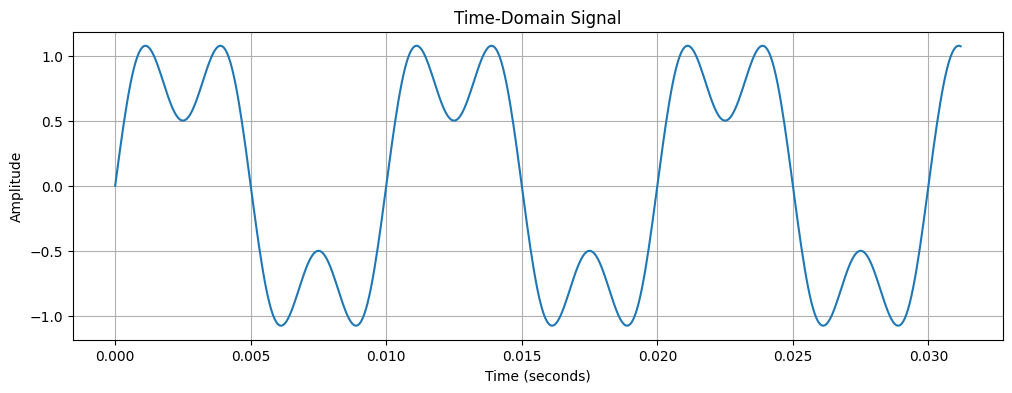

In [3]:
plt.figure(figsize=(12, 4))

plt.plot(t[:500], signal[:500])

plt.title("Time-Domain Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid()
plt.show()

In [4]:
# calculate FFT 

N = len(signal)

X = np.fft.rfft(signal)

frequencies = np.fft.rfftfreq(N, d=1/fs)

In [5]:
# calculate the magnitude spectrum 
magnitude = np.abs(X)

amplitude_spectrum = magnitude / N

# Convert to a one-sided amplitude spectrum
amplitude_spectrum[1:-1] *= 2

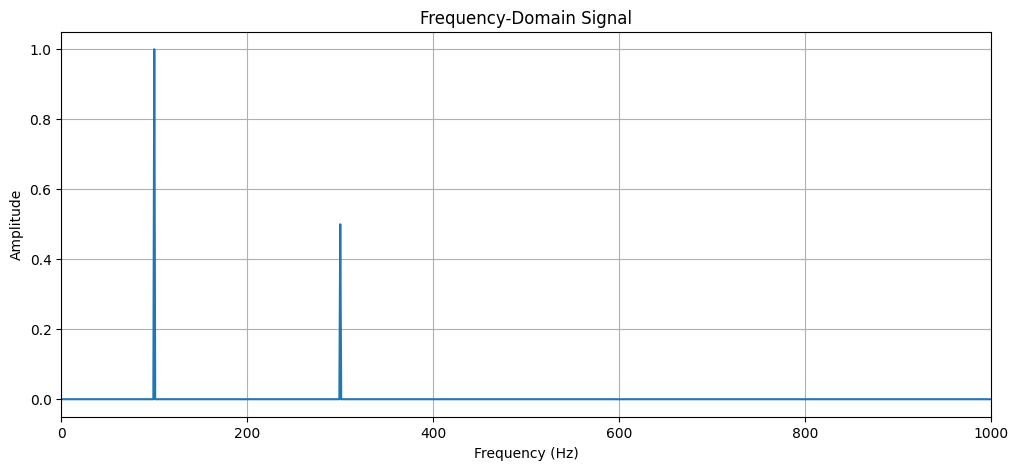

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(frequencies, amplitude_spectrum)

plt.title("Frequency-Domain Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")

plt.xlim(0, 1000)
plt.grid()

plt.show()

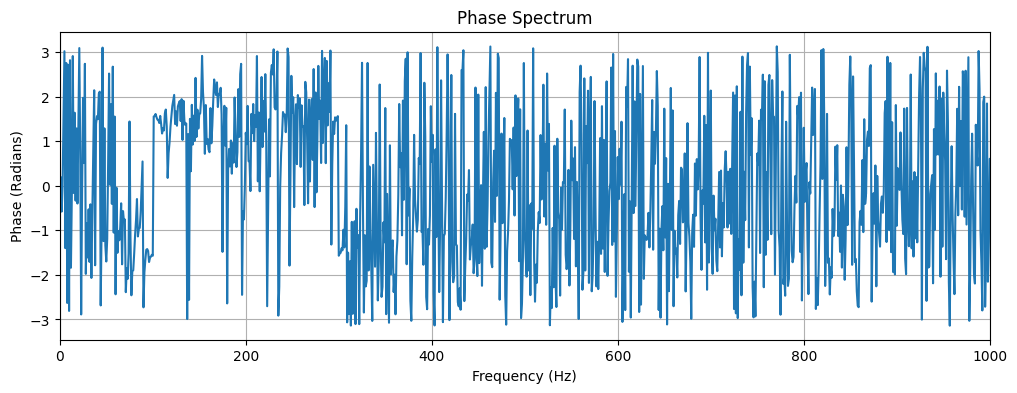

In [7]:
# phase spectrum 

phase = np.angle(X)

plt.figure(figsize=(12, 4))

plt.plot(frequencies, phase)

plt.title("Phase Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase (Radians)")

plt.xlim(0, 1000)
plt.grid()

plt.show()

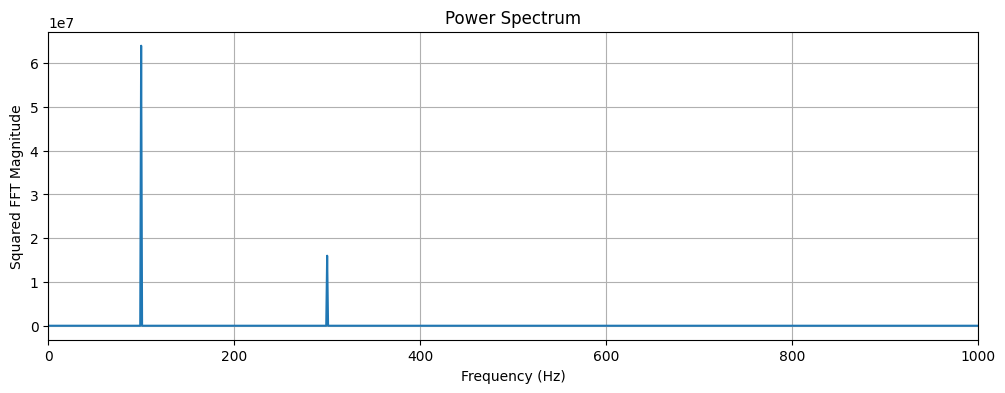

In [8]:
# power spectrum 

power_spectrum = np.abs(X) ** 2

plt.figure(figsize=(12, 4))

plt.plot(frequencies, power_spectrum)

plt.title("Power Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Squared FFT Magnitude")

plt.xlim(0, 1000)
plt.grid()

plt.show()

In [9]:
# doing with actual audio file 

import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

audio, fs = sf.read("audio/raw/sample-speech-1m.mp3")

# Convert stereo audio to mono for this demonstration
if audio.ndim == 2:
    audio = audio.mean(axis=1)

print("Sampling Rate:", fs)
print("Total Samples:", len(audio))
print("Duration:", len(audio) / fs)

Sampling Rate: 22050
Total Samples: 1323119
Duration: 60.00539682539682


In [10]:
start_time = 0.5
end_time = 0.6

start = int(start_time * fs)
end = int(end_time * fs)

segment = audio[start:end]

In [11]:
window = np.hanning(len(segment))

windowed_segment = segment * window

In [12]:
N = len(windowed_segment)

X = np.fft.rfft(windowed_segment)

frequencies = np.fft.rfftfreq(N, d=1/fs)

magnitude = np.abs(X)

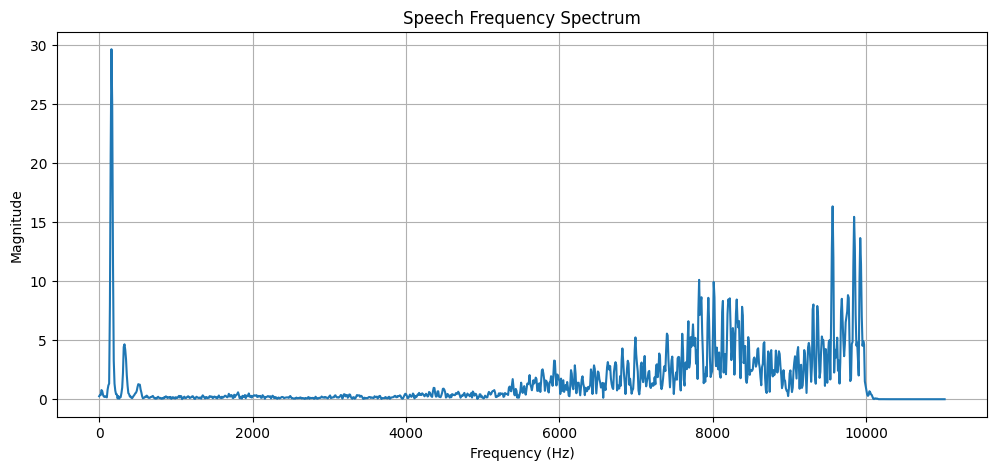

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(frequencies, magnitude)

plt.title("Speech Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")

plt.grid()
plt.show()